# Implementação do FCM(Original) e Obtenção Empírica da Função Tempo

In [7]:
# Lista os arquivos da pasta atual
import os
print("Arquivos aqui:", os.listdir('.'))
# Lista os arquivos da pasta de cima (um nível acima)
print("Arquivos um nível acima:", os.listdir('..'))

Arquivos aqui: ['relatorio_fcm_original.ipynb', 'Rubens.jpg', 'lista_imagens']
Arquivos um nível acima: ['__pycache__', 'fcm_codigo_original', 'FCM_PURO_v3.py', 'Relatório_Credito2_EP', 'experimentador']


In [8]:
imagem_entrada = "Rubens.jpg"          

--- INICIANDO PROCESSAMENTO DE BANCADA ---
Figura de Entrada: Rubens.jpg
Clusters (K): 4


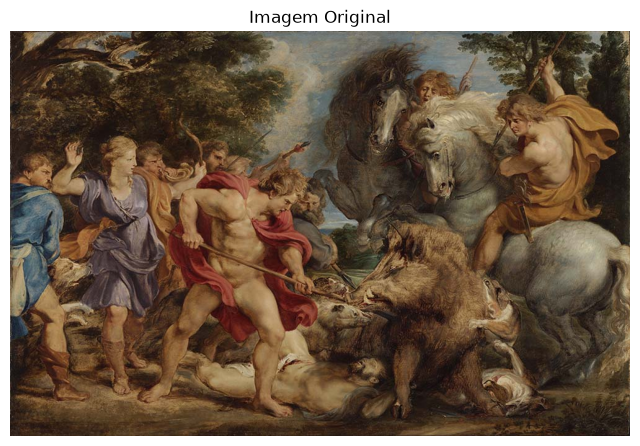

/tmp/ipykernel_465820/3127697586.py:15: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels_2d = list(img.getdata())


-> Convergiu na iteração 39!

[SUCESSO] Processamento finalizado com folga!
Tempo Total de Execução (Bancada): 194.7576 segundos


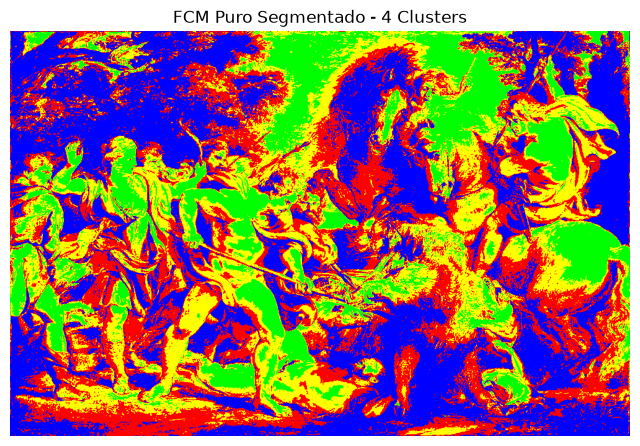

In [9]:
import time
import random
from PIL import Image
import matplotlib.pyplot as plt
import os

def fcm_processar_imagem(img, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Executa o pipeline completo do FCM Puro com proteções contra índice inválido e divisão por zero.
    """
    
    largura, altura = img.size
    
    # Extração segura dos pixels da imagem
    pixels_2d = list(img.getdata())
    
    # =======================c=============================================
    # ALVO: MISSÃO 3 (Structure of Arrays - SoA)
    # A equipe 3 deve DESTRUIR este for. Em vez de uma lista X com sublistas
    # [R, G, B], eles deverão criar três listas gigantes isoladas:
    # X_R = [], X_G = [], X_B = []
    # ====================================================================
    X = []
    for p in pixels_2d:
        X.append([float(p[0]), float(p[1]), float(p[2])])
        
    N = len(X)
    canais = 3
    
    paleta_cores = [
        [255, 0, 0],     # Cluster 0: Vermelho
        [0, 255, 0],     # Cluster 1: Verde
        [0, 0, 255],     # Cluster 2: Azul
        [255, 255, 0],   # Cluster 3: Amarelo
        [255, 0, 255],   # Cluster 4: Magenta
        [0, 255, 255]    # Cluster 5: Ciano
    ]
    
    # ====================================================================
    # ALVO: MISSÃO 1 (Memory Flattening)
    # A equipe 1 deve DESTRUIR a declaração bidimensional de U (lista de listas).
    # U deve ser um vetor achatado (1D) de tamanho N * K.
    # ====================================================================
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0
        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val
        
        for j in range(K):
            if soma_linha == 0.0:
                linha[j] = 1.0 / K
            else:
                linha[j] = linha[j] / soma_linha
        U.append(linha)
        
    # 4. LAÇO PRINCIPAL DO FCM (Puro)
    for iteracao in range(max_iter):
        
        # ====================================================================
        # ALVO: MISSÃO 2 (Fixed Point Math / Fuga da FPU)
        # A equipe 2 terá que modificar este laço e os laços subsequentes
        # para impedir o uso de float e a divisão decimal de numerador por 
        # denominador, usando shifiting (>>).
        # ====================================================================
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0
            
            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m
                
                # ====================================================================
                # ALVO: MISSÃO 4 (Loop Unrolling)
                # A equipe 4 deverá ELIMINAR este laço `for c in range(canais):` 
                # e desdobrar as operações manualmente (num_0 += ..., num_1 += ...)
                # ====================================================================
                for c in range(canais):
                    numerador[c] += u_m * X[i][c]
            
            centroide_j = []
            for c in range(canais):
                if denominador == 0.0:
                    centroide_j.append(0.0)
                else:
                    centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)
            
        U_nova = []
        max_diff = 0.0
        
        # ====================================================================
        # ALVO: MISSÃO 6 (Loop Fission)
        # A equipe 6 deverá DUPLICAR todo este bloco `for i in range(N):`.
        # Um laço roda a tela inteira APENAS calculando e salvando as distâncias 
        # em um array temporário gigante. Um segundo laço roda a tela de novo 
        # calculando a pertinência a partir desse array.
        # ====================================================================
        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K
            
            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff
                distancias[j] = soma_quadrados ** 0.5 
                
                # ====================================================================
                # ALVO: MISSÃO 5 (Early Exit / Poda Condicional)
                # A equipe 5 deverá INJETAR aqui dentro um desvio:
                # Se 'distancias[j]' for maior que um limite arbitrário X, break.
                # ====================================================================
                
            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j: 
                            linha_nova[k] = 0.0
                    break
                    
                soma_dist = 0.0
                for k in range(K):
                    d_k = distancias[k] if distancias[k] > 0.0 else 1e-10
                    razao = distancias[j] / d_k
                    soma_dist += razao ** (2.0 / (m - 1.0))
                
                pertinencia = 1.0 / soma_dist if soma_dist > 0.0 else (1.0 / K)
                linha_nova[j] = pertinencia
                
                diff_u = pertinencia - U[i][j]
                if diff_u < 0: 
                    diff_u = -diff_u
                if diff_u > max_diff: 
                    max_diff = diff_u
                
            U_nova.append(linha_nova)
            
        # O U TEM QUE SER ATUALIZADO AQUI FORA DO LAÇO DE PIXELS!
        U = U_nova
            
        if max_diff < epsilon:
            print(f"-> Convergiu na iteração {iteracao}!")
            break
            
    # 5. FASE 5: COLORIZAÇÃO POR PERTINÊNCIA MÁXIMA
    pixels_segmentados_lista = []
    for i in range(N):
        maior_pertinencia = -1.0
        cluster_vencedor = 0
        for j in range(K):
            if U[i][j] > maior_pertinencia:
                maior_pertinencia = U[i][j]
                cluster_vencedor = j
                
        cor = paleta_cores[cluster_vencedor % len(paleta_cores)]
        pixels_segmentados_lista.append((cor[0], cor[1], cor[2]))
        
    # 6. RESHAPE MANUAL E SALVAMENTO
    imagem_final = Image.new("RGB", (largura, altura))
    imagem_final.putdata(pixels_segmentados_lista)
    
    return C, U, imagem_final

# ==============================================================
# MAIN 
# ==============================================================
if __name__ == "__main__":
    # Defina o caminho da sua imagem real de teste e o nome da saída
    # imagem_entrada = "images/brain_256.jpeg"          
    
    K_clusters = 4                        
    fator_m = 2.0                         
    iteracoes_max = 100                    
    limite_epsilon = 0.001                
    
    print(f"--- INICIANDO PROCESSAMENTO DE BANCADA ---")
    print(f"Figura de Entrada: {imagem_entrada}")
    print(f"Clusters (K): {K_clusters}")

    # 1. LEITURA DA IMAGEM DO DISCO
    try:
        imagem = Image.open(imagem_entrada).convert("RGB")

        plt.figure(figsize=(8, 8))
        plt.title(f"Imagem Original")
        plt.imshow(imagem)
        plt.axis('off')
        plt.show()
        
        t0 = time.perf_counter()
        
        # ATENÇÃO: Agora pegando os 3 retornos corretamente
        centroides, pertinencias, imagem_segmentada = fcm_processar_imagem(
            img=imagem,
            K=K_clusters,
            m=fator_m,
            max_iter=iteracoes_max,
            epsilon=limite_epsilon
        )
        
        t1 = time.perf_counter()
        tempo_total = t1 - t0
        
        print(f"\n[SUCESSO] Processamento finalizado com folga!")
        print(f"Tempo Total de Execução (Bancada): {tempo_total:.4f} segundos")
        
        # Plotagem usando Matplotlib
        plt.figure(figsize=(8, 8))
        plt.title(f"FCM Puro Segmentado - {K_clusters} Clusters")
        plt.imshow(imagem_segmentada)
        plt.axis('off')
        plt.show()
        
    except FileNotFoundError:
        print(f"\n[ERRO] O arquivo '{imagem_entrada}' não foi encontrado.")
    except Exception as e:
        print(f"\n[ERRO INESPERADO] Ocorreu uma falha durante o processamento: {e}")
    

In [10]:
# Diretório com a lista de imagens para teste
pasta_imagens = "lista_imagens"


--- INICIANDO PROCESSAMENTO DE BANCADA (FCM ORIGINAL) ---
Diretório de Imagens: lista_imagens
Clusters (K): 4

Mapeando imagens e calculando 'n' (apenas cabeçalhos)...
11 imagens ordenadas prontas para processamento.

Carregando 1x1.png para a RAM (n=1, dimensões=1x1)...


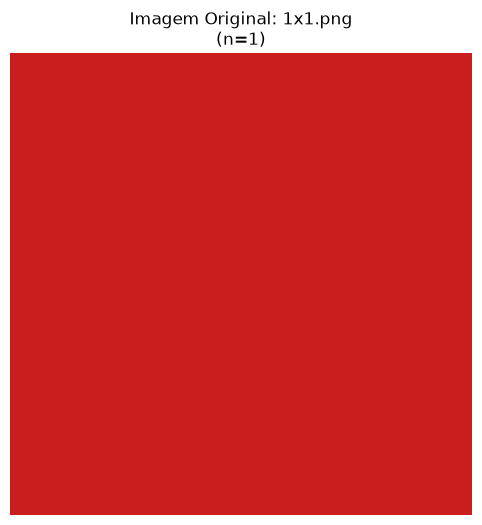

-> Convergiu na iteração 1!

[SUCESSO] Processamento de 1x1.png finalizado com folga!
Tempo Total de Execução (Bancada): 0.0685 segundos


/tmp/ipykernel_465820/4024831393.py:16: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels_2d = list(img.getdata())


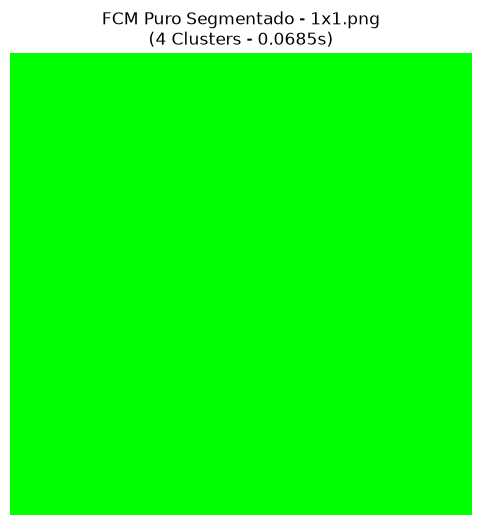

Análise de 1x1.png concluída. Memória liberada.

Carregando 2x2.png para a RAM (n=4, dimensões=2x2)...


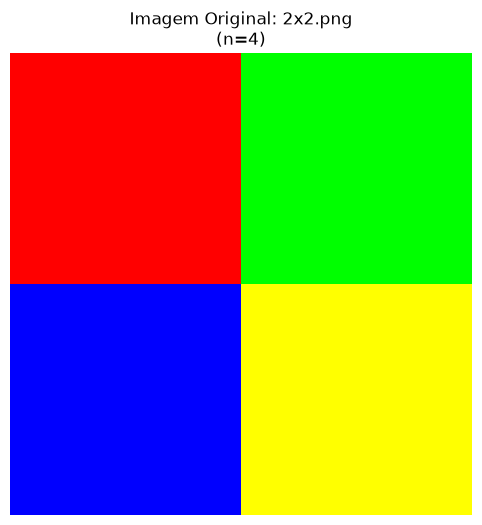

-> Convergiu na iteração 5!

[SUCESSO] Processamento de 2x2.png finalizado com folga!
Tempo Total de Execução (Bancada): 0.0003 segundos


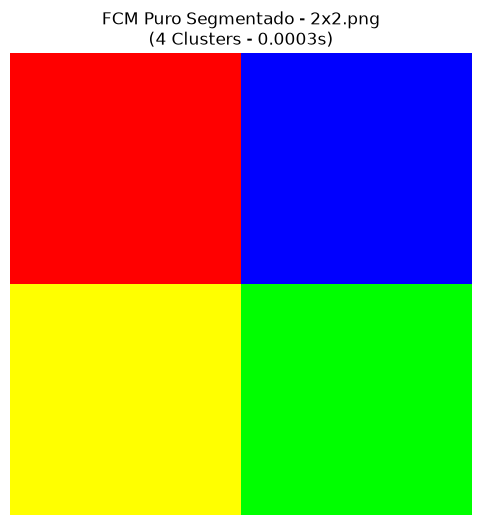

Análise de 2x2.png concluída. Memória liberada.

Carregando cor_unica.png para a RAM (n=16384, dimensões=128x128)...


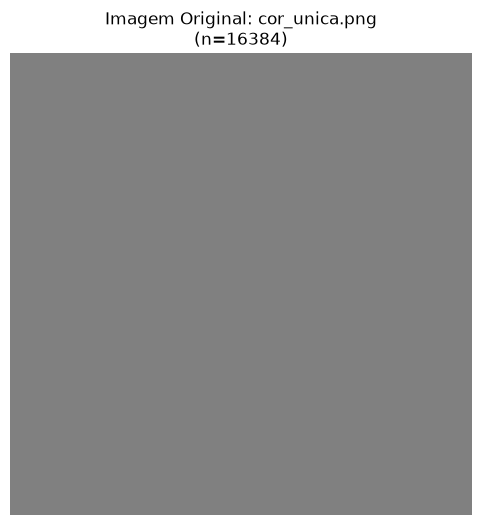

-> Convergiu na iteração 0!

[SUCESSO] Processamento de cor_unica.png finalizado com folga!
Tempo Total de Execução (Bancada): 0.0780 segundos


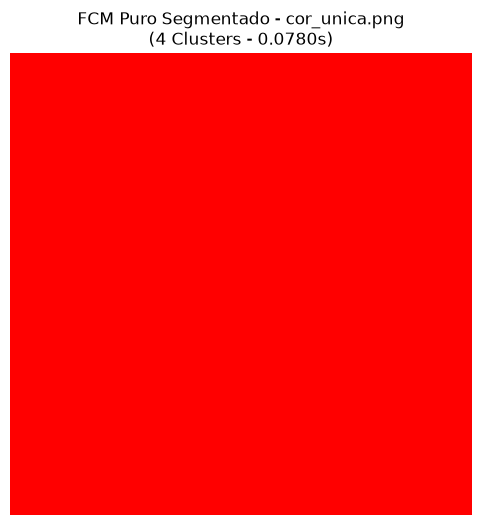

Análise de cor_unica.png concluída. Memória liberada.

Carregando gradiente_h.png para a RAM (n=65536, dimensões=256x256)...


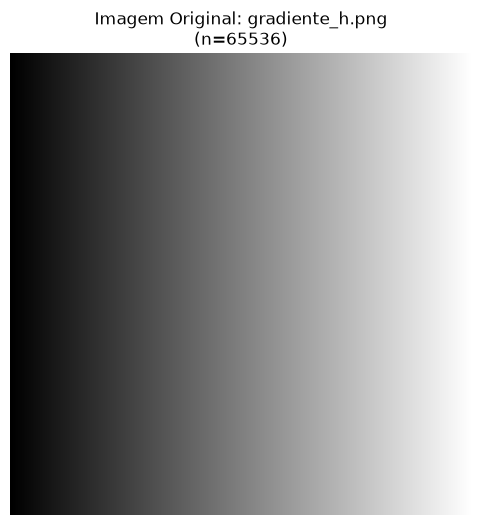

-> Convergiu na iteração 19!

[SUCESSO] Processamento de gradiente_h.png finalizado com folga!
Tempo Total de Execução (Bancada): 9.0963 segundos


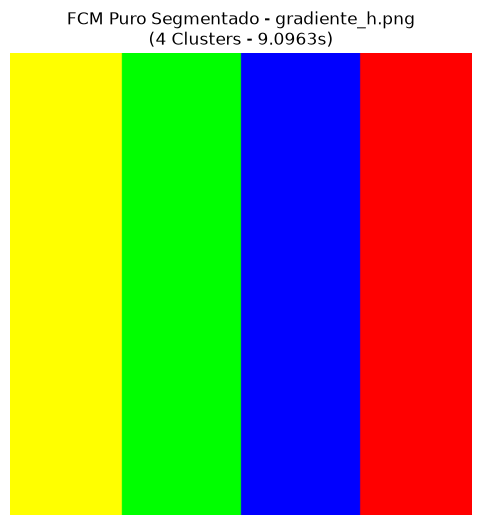

Análise de gradiente_h.png concluída. Memória liberada.

Carregando brain_256.jpeg para a RAM (n=65536, dimensões=256x256)...


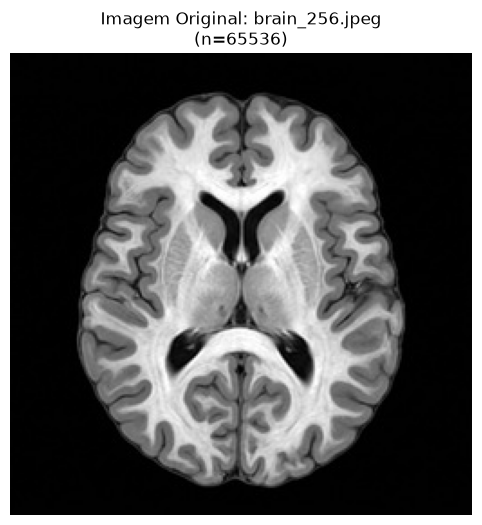

-> Convergiu na iteração 22!

[SUCESSO] Processamento de brain_256.jpeg finalizado com folga!
Tempo Total de Execução (Bancada): 10.8316 segundos


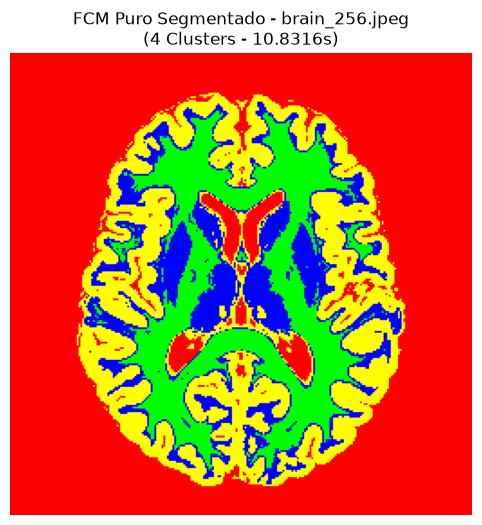

Análise de brain_256.jpeg concluída. Memória liberada.

Carregando regioes_ruido.png para a RAM (n=65536, dimensões=256x256)...


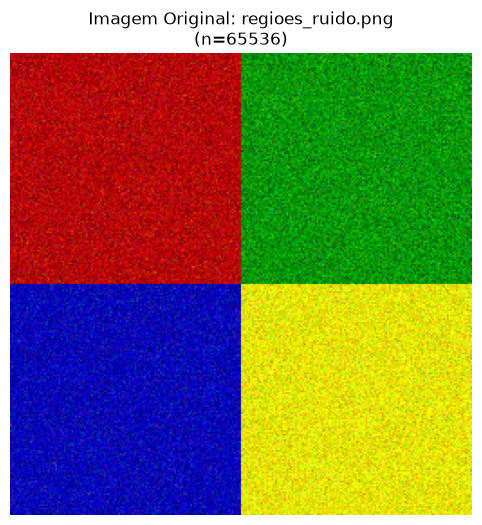

-> Convergiu na iteração 14!

[SUCESSO] Processamento de regioes_ruido.png finalizado com folga!
Tempo Total de Execução (Bancada): 7.2027 segundos


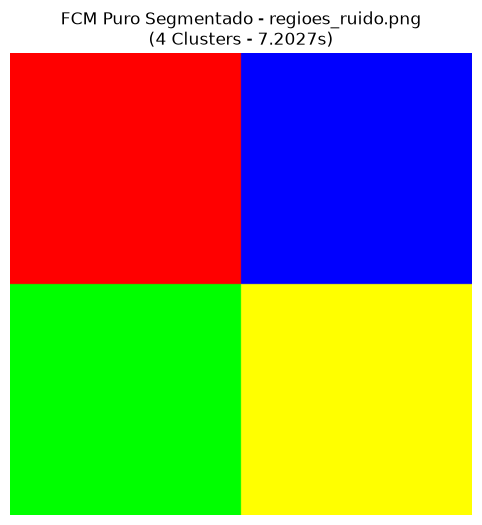

Análise de regioes_ruido.png concluída. Memória liberada.

Carregando preto_branco.png para a RAM (n=65536, dimensões=256x256)...


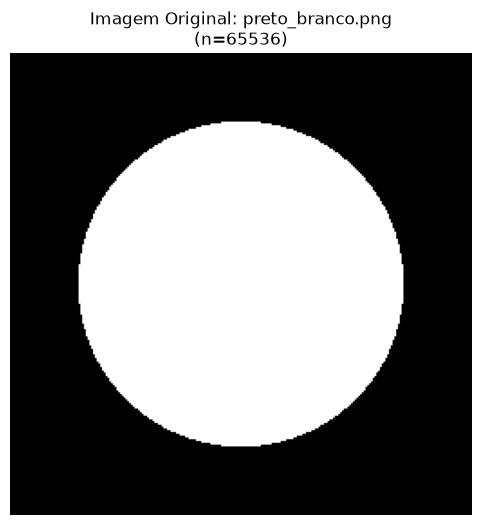


[SUCESSO] Processamento de preto_branco.png finalizado com folga!
Tempo Total de Execução (Bancada): 45.4666 segundos


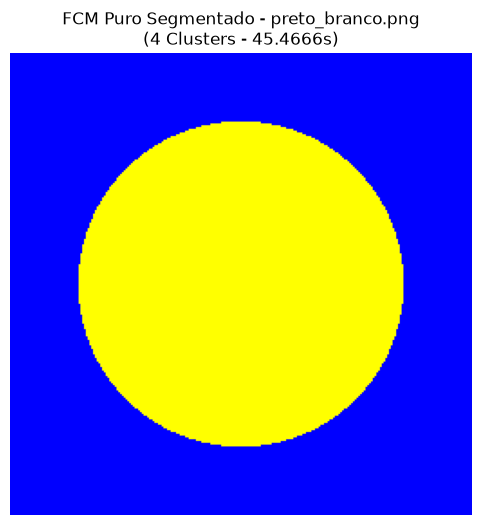

Análise de preto_branco.png concluída. Memória liberada.

Carregando gradiente_radial.png para a RAM (n=65536, dimensões=256x256)...


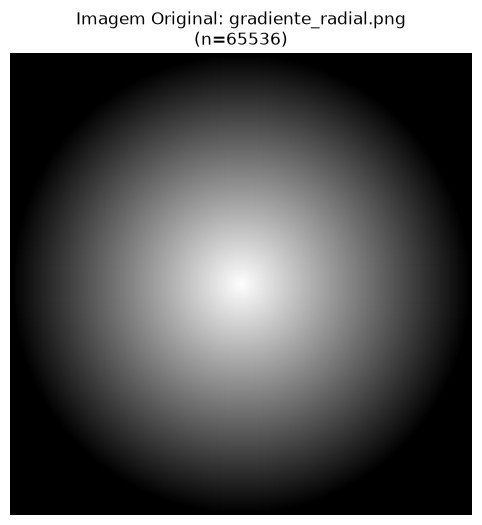

-> Convergiu na iteração 40!

[SUCESSO] Processamento de gradiente_radial.png finalizado com folga!
Tempo Total de Execução (Bancada): 17.8318 segundos


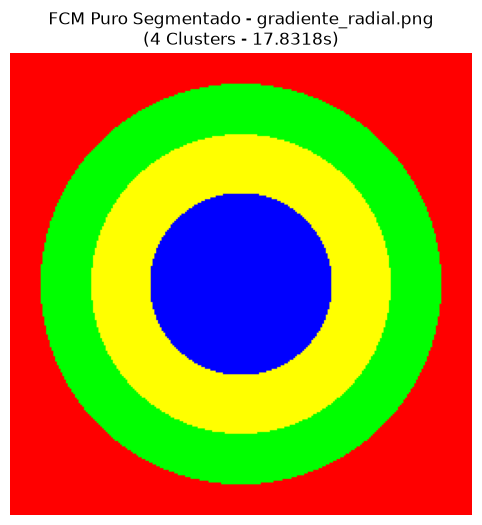

Análise de gradiente_radial.png concluída. Memória liberada.

Carregando regioes.png para a RAM (n=65536, dimensões=256x256)...


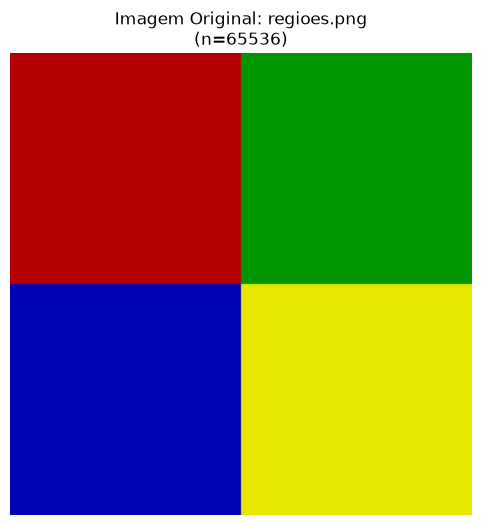

-> Convergiu na iteração 12!

[SUCESSO] Processamento de regioes.png finalizado com folga!
Tempo Total de Execução (Bancada): 5.8434 segundos


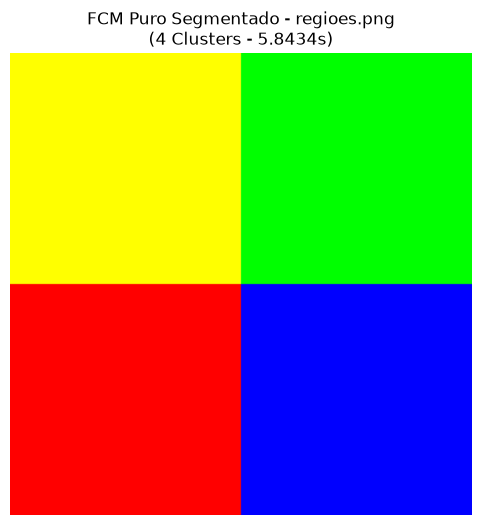

Análise de regioes.png concluída. Memória liberada.

Carregando natural.jpeg para a RAM (n=262144, dimensões=512x512)...


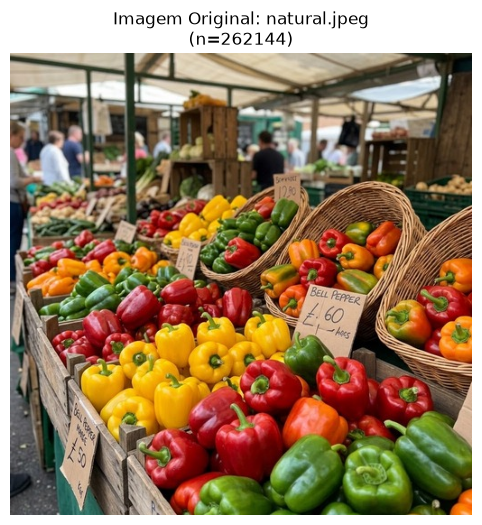

-> Convergiu na iteração 37!

[SUCESSO] Processamento de natural.jpeg finalizado com folga!
Tempo Total de Execução (Bancada): 64.7218 segundos


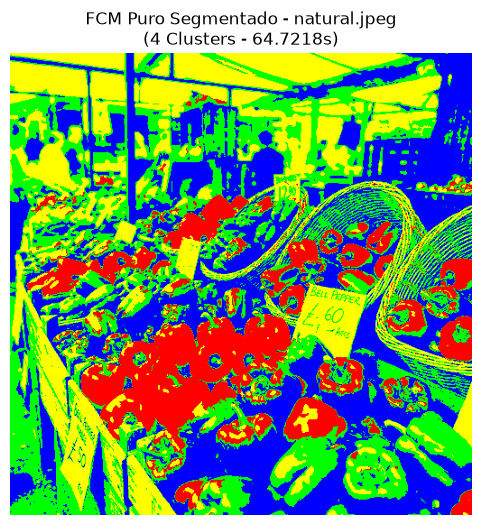

Análise de natural.jpeg concluída. Memória liberada.

Carregando img_output.png para a RAM (n=640000, dimensões=800x800)...


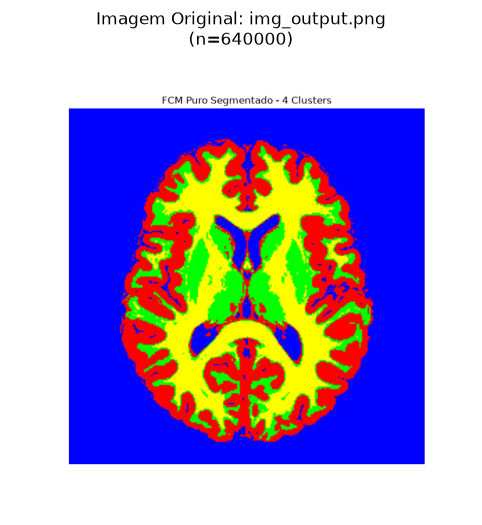

-> Convergiu na iteração 25!

[SUCESSO] Processamento de img_output.png finalizado com folga!
Tempo Total de Execução (Bancada): 108.6372 segundos


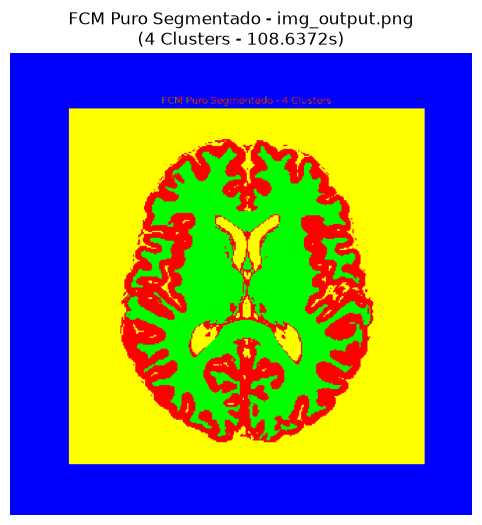

Análise de img_output.png concluída. Memória liberada.

   RESUMO GERAL DAS EXECUÇÕES DO FCM
                 arquivo       n  k     tempo_s status
0                1x1.png       1  4    0.068537     OK
1                2x2.png       4  4    0.000282     OK
2          cor_unica.png   16384  4    0.078018     OK
3        gradiente_h.png   65536  4    9.096256     OK
4         brain_256.jpeg   65536  4   10.831563     OK
5      regioes_ruido.png   65536  4    7.202669     OK
6       preto_branco.png   65536  4   45.466622     OK
7   gradiente_radial.png   65536  4   17.831780     OK
8            regioes.png   65536  4    5.843353     OK
9           natural.jpeg  262144  4   64.721773     OK
10        img_output.png  640000  4  108.637174     OK


In [11]:
import time
import random
from PIL import Image
import matplotlib.pyplot as plt
import os
import pandas as pd

def fcm_processar_imagem(img, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Executa o pipeline completo do FCM Puro com proteções contra índice inválido e divisão por zero.
    """
    
    largura, altura = img.size
    
    # Extração segura dos pixels da imagem
    pixels_2d = list(img.getdata())
    
    # =======================c=============================================
    # ALVO: MISSÃO 3 (Structure of Arrays - SoA)
    # A equipe 3 deve DESTRUIR este for. Em vez de uma lista X com sublistas
    # [R, G, B], eles deverão criar três listas gigantes isoladas:
    # X_R = [], X_G = [], X_B = []
    # ====================================================================
    X = []
    for p in pixels_2d:
        X.append([float(p[0]), float(p[1]), float(p[2])])
        
    N = len(X)
    canais = 3
    
    paleta_cores = [
        [255, 0, 0],     # Cluster 0: Vermelho
        [0, 255, 0],     # Cluster 1: Verde
        [0, 0, 255],     # Cluster 2: Azul
        [255, 255, 0],   # Cluster 3: Amarelo
        [255, 0, 255],   # Cluster 4: Magenta
        [0, 255, 255]    # Cluster 5: Ciano
    ]
    
    # ====================================================================
    # ALVO: MISSÃO 1 (Memory Flattening)
    # A equipe 1 deve DESTRUIR a declaração bidimensional de U (lista de listas).
    # U deve ser um vetor achatado (1D) de tamanho N * K.
    # ====================================================================
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0
        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val
        
        for j in range(K):
            if soma_linha == 0.0:
                linha[j] = 1.0 / K
            else:
                linha[j] = linha[j] / soma_linha
        U.append(linha)
        
    # 4. LAÇO PRINCIPAL DO FCM (Puro)
    for iteracao in range(max_iter):
        
        # ====================================================================
        # ALVO: MISSÃO 2 (Fixed Point Math / Fuga da FPU)
        # A equipe 2 terá que modificar este laço e os laços subsequentes
        # para impedir o uso de float e a divisão decimal de numerador por 
        # denominador, usando shifiting (>>).
        # ====================================================================
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0
            
            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m
                
                # ====================================================================
                # ALVO: MISSÃO 4 (Loop Unrolling)
                # A equipe 4 deverá ELIMINAR este laço `for c in range(canais):` 
                # e desdobrar as operações manualmente (num_0 += ..., num_1 += ...)
                # ====================================================================
                for c in range(canais):
                    numerador[c] += u_m * X[i][c]
            
            centroide_j = []
            for c in range(canais):
                if denominador == 0.0:
                    centroide_j.append(0.0)
                else:
                    centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)
            
        U_nova = []
        max_diff = 0.0
        
        # ====================================================================
        # ALVO: MISSÃO 6 (Loop Fission)
        # A equipe 6 deverá DUPLICAR todo este bloco `for i in range(N):`.
        # Um laço roda a tela inteira APENAS calculando e salvando as distâncias 
        # em um array temporário gigante. Um segundo laço roda a tela de novo 
        # calculando a pertinência a partir desse array.
        # ====================================================================
        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K
            
            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff
                distancias[j] = soma_quadrados ** 0.5 
                
                # ====================================================================
                # ALVO: MISSÃO 5 (Early Exit / Poda Condicional)
                # A equipe 5 deverá INJETAR aqui dentro um desvio:
                # Se 'distancias[j]' for maior que um limite arbitrário X, break.
                # ====================================================================
                
            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j: 
                            linha_nova[k] = 0.0
                    break
                    
                soma_dist = 0.0
                for k in range(K):
                    d_k = distancias[k] if distancias[k] > 0.0 else 1e-10
                    razao = distancias[j] / d_k
                    soma_dist += razao ** (2.0 / (m - 1.0))
                
                pertinencia = 1.0 / soma_dist if soma_dist > 0.0 else (1.0 / K)
                linha_nova[j] = pertinencia
                
                diff_u = pertinencia - U[i][j]
                if diff_u < 0: 
                    diff_u = -diff_u
                if diff_u > max_diff: 
                    max_diff = diff_u
                
            U_nova.append(linha_nova)
            
        # O U TEM QUE SER ATUALIZADO AQUI FORA DO LAÇO DE PIXELS!
        U = U_nova
            
        if max_diff < epsilon:
            print(f"-> Convergiu na iteração {iteracao}!")
            break
            
    # 5. FASE 5: COLORIZAÇÃO POR PERTINÊNCIA MÁXIMA
    pixels_segmentados_lista = []
    for i in range(N):
        maior_pertinencia = -1.0
        cluster_vencedor = 0
        for j in range(K):
            if U[i][j] > maior_pertinencia:
                maior_pertinencia = U[i][j]
                cluster_vencedor = j
                
        cor = paleta_cores[cluster_vencedor % len(paleta_cores)]
        pixels_segmentados_lista.append((cor[0], cor[1], cor[2]))
        
    # 6. RESHAPE MANUAL E SALVAMENTO
    imagem_final = Image.new("RGB", (largura, altura))
    imagem_final.putdata(pixels_segmentados_lista)
    
    return C, U, imagem_final

# ==============================================================
# MAIN 
# ==============================================================
if __name__ == "__main__":
    # Diretório com a lista de imagens para processamento
    img_dir = pasta_imagens if 'pasta_imagens' in locals() and os.path.exists(pasta_imagens) else "lista_imagens"
    if not os.path.exists(img_dir) and os.path.exists("fcm_codigo_original/lista_imagens"):
        img_dir = "fcm_codigo_original/lista_imagens"
        
    K_clusters = 4                        
    fator_m = 2.0                         
    iteracoes_max = 100                    
    limite_epsilon = 0.001                
    
    print(f"--- INICIANDO PROCESSAMENTO DE BANCADA (FCM ORIGINAL) ---")
    print(f"Diretório de Imagens: {img_dir}")
    print(f"Clusters (K): {K_clusters}")

    # ==========================================
    # 2. Descoberta e Ordenação Ligeira (Sem estourar RAM)
    # Similar ao experimentador_EP_2026.2
    # ==========================================
    print("\nMapeando imagens e calculando 'n' (apenas cabeçalhos)...")
    arquivos_n = []

    # Varre os arquivos no diretório especificado
    if os.path.exists(img_dir):
        for filename in os.listdir(img_dir):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                filepath = os.path.join(img_dir, filename)
                
                # Image.open lê apenas os metadados. Não aloca a matriz de pixels.
                with Image.open(filepath) as img:
                    w, h = img.size
                    n = w * h
                    arquivos_n.append({'arquivo': filename, 'caminho': filepath, 'n': n, 'largura': w, 'altura': h})

    # Ordena a lista de dicionários pelo valor de 'n' crescente
    arquivos_n = sorted(arquivos_n, key=lambda x: x['n'])

    print(f"{len(arquivos_n)} imagens ordenadas prontas para processamento.")

    # ==========================================
    # 3. Execução (Carregando sob demanda)
    # ==========================================
    resultados = []

    for item in arquivos_n:
        n = item['n']
        filepath = item['caminho']
        nome_arquivo = item['arquivo']
        
        print("\n" + "=" * 60)
        print(f"Carregando {nome_arquivo} para a RAM (n={n}, dimensões={item['largura']}x{item['altura']})...")
        print("=" * 60)
        
        try:
            # Carrega a imagem real para a RAM apenas no momento de usar
            with Image.open(filepath) as img_raw:
                imagem = img_raw.convert("RGB")

            plt.figure(figsize=(6, 6))
            plt.title(f"Imagem Original: {nome_arquivo}\n(n={n})")
            plt.imshow(imagem)
            plt.axis('off')
            plt.show()
            
            t0 = time.perf_counter()
            
            # ATENÇÃO: Agora pegando os 3 retornos corretamente
            centroides, pertinencias, imagem_segmentada = fcm_processar_imagem(
                img=imagem,
                K=K_clusters,
                m=fator_m,
                max_iter=iteracoes_max,
                epsilon=limite_epsilon
            )
            
            t1 = time.perf_counter()
            tempo_total = t1 - t0
            
            print(f"\n[SUCESSO] Processamento de {nome_arquivo} finalizado com folga!")
            print(f"Tempo Total de Execução (Bancada): {tempo_total:.4f} segundos")
            
            # Plotagem usando Matplotlib
            plt.figure(figsize=(6, 6))
            plt.title(f"FCM Puro Segmentado - {nome_arquivo}\n({K_clusters} Clusters - {tempo_total:.4f}s)")
            plt.imshow(imagem_segmentada)
            plt.axis('off')
            plt.show()
            
            resultados.append({
                'arquivo': nome_arquivo,
                'n': n,
                'largura': item['largura'],
                'altura': item['altura'],
                'k': K_clusters,
                'tempo_s': tempo_total,
                'status': 'OK'
            })
            
            # Libera a RAM explicitamente antes de carregar a próxima imagem
            del imagem
            del imagem_segmentada
            del centroides
            del pertinencias
            print(f"Análise de {nome_arquivo} concluída. Memória liberada.")
            
        except FileNotFoundError:
            print(f"\n[ERRO] O arquivo '{filepath}' não foi encontrado.")
            resultados.append({
                'arquivo': nome_arquivo,
                'n': n,
                'largura': item['largura'],
                'altura': item['altura'],
                'k': K_clusters,
                'tempo_s': None,
                'status': 'FileNotFoundError'
            })
        except Exception as e:
            print(f"\n[ERRO INESPERADO] Ocorreu uma falha durante o processamento de {nome_arquivo}: {e}")
            resultados.append({
                'arquivo': nome_arquivo,
                'n': n,
                'largura': item['largura'],
                'altura': item['altura'],
                'k': K_clusters,
                'tempo_s': None,
                'status': f'ERRO: {e}'
            })

    # ==========================================
    # 4. Resumo dos Dados
    # ==========================================
    if resultados:
        df_resultados = pd.DataFrame(resultados)
        print("\n" + "=" * 60)
        print("   RESUMO GERAL DAS EXECUÇÕES DO FCM")
        print("=" * 60)
        print(df_resultados[['arquivo', 'n', 'k', 'tempo_s', 'status']])

